# Turtle Breakout 02 — the TB 01 turtle portfolio against proper benchmarks

Pre-registration: `discussions/Turtle_Breakout/003_claude_tb02_preregistration.md`. Code: `src/data_engineering/modeling/turtle_benchmarks.py`.

The strategy is the unchanged TB 01 primary (daily, long only, BTC/ETH/SOL/XRP, 2% HWM risk, fees + slippage + funding). TB 01's buy-and-hold was never rebalanced and was distorted by funding on SOL's grown notional. Here it must beat, on Sharpe (21-day block bootstrap, q2.5 > 0), **all three** constant-mix benchmarks at its own mean leverage:

- **B1** perpetuals, equal weight, rebalanced monthly, with funding
- **B2** perpetuals, equal weight, rebalanced daily, with funding
- **B3** spot proxy (perp prices without funding), equal weight, rebalanced monthly

Reported: B4 inverse-volatility weights; B1 at the strategy's realised volatility; alpha/beta vs B1; years; halves; rolling Sharpe.

Environment: `TB01_DATA_DIR` (as TB 01), `TB02_SYNTHETIC=1`.

In [1]:
import os, sys, json, time, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_benchmarks as bm

SYNTHETIC = os.getenv('TB02_SYNTHETIC', '0') == '1'
ASSETS = list(tb.ASSETS)
P = tb.Params(); BP = bm.BParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb02-')) / '02'; BP = bm.BParams(n_boot=300)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '02'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
for t in ('test_turtle_breakout.py', 'test_turtle_benchmarks.py'):
    chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', t], cwd=str(ROOT), env=env, capture_output=True, text=True)
    print(t, chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0, t
print(json.dumps(bm.registration(BP), indent=1))

test_turtle_breakout.py OK
test_turtle_benchmarks.py OK
{
 "vol_window_days": 60,
 "nw_lags": 5,
 "block_days": 21,
 "n_boot": 2000,
 "seed": 20261025,
 "status": "PREREGISTERED_TB003",
 "version": "TB02-0.1.0",
 "strategy": "TB 01 primary, unchanged (turtle_breakout Params defaults)",
 "gated": [
  "B1 perp monthly",
  "B2 perp daily",
  "B3 spot-proxy monthly"
 ],
 "reported": [
  "B4 inverse-vol perp monthly",
  "B1 at equal realised vol",
  "alpha/beta vs B1 (L=1)",
  "years",
  "halves",
  "rolling 365d Sharpe"
 ],
 "rule": "each gated benchmark: Sharpe diff 21d block bootstrap q2.5 > 0; verdict needs all three"
}


## 1. Data and the unchanged TB 01 strategy

In [2]:
T0 = time.time(); DATA_D = {}
for k, a in enumerate(ASSETS):
    if SYNTHETIC:
        b = tb.synthetic_5m(2200, seed=40 + k, trend=0.0, start='2019-11-01'); f = tb.synthetic_funding(b, 0.0001)
    else:
        b = tb.bars_5m(pd.read_parquet(DATA / f'{a}USDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
        f = tb.funding_events(pd.read_parquet(DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'))
    DATA_D[a] = tb.prepare_asset(a, b, f, P); print(a, f'{time.time() - T0:.0f}s')
END = min(d.end[-1] for d in DATA_D.values())
E, T, ST = tb.simulate(DATA_D, P, start=tb.COMMON_START, end=END)
m = tb.metrics(E, T); LEV = ST['mean_gross_leverage']
print(json.dumps({k: m[k] for k in ('start', 'end', 'cagr', 'sharpe', 'max_dd', 'trades', 'final_equity')}, default=float), '| mean leverage', round(LEV, 4))
ref = ROOT / 'notebooks' / 'Turtle_Breakout' / '01' / '01_decision.json'
if not SYNTHETIC and ref.exists():
    r = json.loads(ref.read_text())['primary_metrics']
    print('TB 01 reproduced (same end date -> same trades):', r['end'] == m['end'] and r['trades'] == m['trades'], '| TB 01:', r['end'], r['trades'], round(r['cagr'], 4))

BTC 1s
ETH 3s
SOL 4s
XRP 5s
{"start": "2020-10-15", "end": "2026-10-24", "cagr": 0.745298491464911, "sharpe": 1.565860810872366, "max_dd": -0.3606574409394919, "trades": 180, "final_equity": 2863169.1561331195} | mean leverage 0.4124
TB 01 reproduced (same end date -> same trades): True | TB 01: 2026-10-24 180 0.7453


## 2. Benchmarks

In [3]:
Cp, Fp = bm.daily_panel(DATA_D, tb.COMMON_START, END)
COST = P.fee + P.slip
B = {'B1 perp monthly': bm.constant_mix(Cp, Fp, LEV, 'M', True, COST),
     'B2 perp daily': bm.constant_mix(Cp, Fp, LEV, 'D', True, COST),
     'B3 spot-proxy monthly': bm.constant_mix(Cp, Fp, LEV, 'M', False, COST),
     'B4 inverse-vol perp monthly': bm.constant_mix(Cp, Fp, LEV, 'M', True, COST, weights='invvol', vol_window=BP.vol_window_days)}
VOL_S = bm.realised_vol(E)
B['B1 at strategy vol'], L_VOL = bm.vol_matched(Cp, Fp, VOL_S, COST, L0=LEV)
B['B1 perp monthly x1'] = bm.constant_mix(Cp, Fp, 1.0, 'M', True, COST)
rows = {'strategy': {**m, 'vol': VOL_S, 'leverage': LEV}}
for k, v in B.items():
    rows[k] = {**tb.metrics(v), 'vol': bm.realised_vol(v), 'leverage': L_VOL if 'strategy vol' in k else (1.0 if 'x1' in k else LEV)}
TAB = pd.DataFrame(rows).T[['cagr', 'sharpe', 'max_dd', 'vol', 'leverage', 'total_return', 'final_equity']].astype(float)
display(TAB.round(3))

,cagr,sharpe,max_dd,vol,leverage,total_return,final_equity
strategy,0.745,1.566,-0.361,0.408,0.412,27.632,2863169.156
B1 perp monthly,0.321,1.064,-0.464,0.305,0.412,4.341,534013.176
B2 perp daily,0.268,0.936,-0.477,0.303,0.412,3.184,418246.742
B3 spot-proxy monthly,0.382,1.213,-0.466,0.305,0.412,5.999,699716.120
B4 inverse-vol perp monthly,0.273,0.977,-0.452,0.290,0.412,3.271,426951.206
B1 at strategy vol,0.410,1.047,-0.580,0.408,0.555,6.930,792696.307
B1 perp monthly x1,0.592,1.001,-0.826,0.736,1.000,15.430,1641974.714


## 3. Pre-registered decision (all three must pass)

In [4]:
gated = {'B1': B['B1 perp monthly'], 'B2': B['B2 perp daily'], 'B3': B['B3 spot-proxy monthly']}
TESTS = {k: bm.sharpe_diff(E, v, BP, BP.seed + i) for i, (k, v) in enumerate(gated.items())}
DEC = bm.decide(TESTS)
display(pd.DataFrame(TESTS).T.round(3)); print('VERDICT:', DEC['verdict'])

,sharpe_strategy,sharpe_benchmark,diff,lo,hi,pass,days
B1,1.566575,1.063787,0.502788,-0.084434,1.112202,False,2199
B2,1.566575,0.936339,0.630236,-0.031181,1.293868,False,2199
B3,1.566575,1.212871,0.353705,-0.322802,0.973213,False,2199


VERDICT: FAILS_B1_B2_B3


## 4. Reported: equal-risk comparison, alpha/beta, years, halves

In [5]:
rep = {k: bm.sharpe_diff(E, B[k], BP, BP.seed + 10 + i) for i, k in enumerate(['B4 inverse-vol perp monthly', 'B1 at strategy vol'])}
display(pd.DataFrame(rep).T.round(3))
AB = bm.alpha_beta(E, B['B1 perp monthly x1'], BP.nw_lags)
print('alpha/beta vs B1 (L=1):', {k: round(v, 4) for k, v in AB.items()})
YR = pd.DataFrame({'strategy': tb.yearly(E), **{k: tb.yearly(B[k]) for k in ('B1 perp monthly', 'B3 spot-proxy monthly', 'B1 at strategy vol')}})
display((100 * YR).round(1))
HV = []
for lab, a, b in (('2020-10 -> 2023-06', tb.COMMON_START, tb.HALF_SPLIT), ('2023-07 -> end', tb.HALF_SPLIT, END + pd.Timedelta(days=1))):
    cut = lambda S: S[(S.index >= a) & (S.index < b)]
    for k in ('B1', 'B2', 'B3'):
        r = bm.sharpe_diff(cut(E), cut(gated[k]), BP, BP.seed + 20)
        HV.append({'window': lab, 'benchmark': k, **r})
HV = pd.DataFrame(HV); display(HV.round(3))

,sharpe_strategy,sharpe_benchmark,diff,lo,hi,pass,days
B4 inverse-vol perp monthly,1.566575,0.97726,0.589315,-0.048043,1.184444,False,2199
B1 at strategy vol,1.566575,1.047232,0.519343,-0.110918,1.128584,False,2199


alpha/beta vs B1 (L=1): {'alpha_daily': 0.0011, 'alpha_annual_simple': 0.3899, 'beta': 0.3383, 't_alpha_nw': 2.9022, 't_beta_nw': 9.5979, 'corr': 0.61, 'days': 2199}


,strategy,B1 perp monthly,B3 spot-proxy monthly,B1 at strategy vol
2020,59.4,23.6,25.3,31.4
2021,123.6,182.3,233.5,276.0
2022,-20.4,-36.8,-37.6,-47.3
2023,213.9,73.8,78.8,106.1
2024,107.4,53.7,62.5,71.7
2025,17.5,-3.9,-2.4,-6.2
2026,32.0,-5.7,-5.4,-8.3


,window,benchmark,sharpe_strategy,sharpe_benchmark,diff,lo,hi,pass,days
0,2020-10 -> 2023-06,B1,1.449,1.259,0.189,-0.725,1.086,False,988
1,2020-10 -> 2023-06,B2,1.449,1.093,0.356,-0.639,1.289,False,988
2,2020-10 -> 2023-06,B3,1.449,1.444,0.004,-0.972,0.942,False,988
3,2023-07 -> end,B1,1.664,0.878,0.787,-0.020,1.492,False,1210
4,2023-07 -> end,B2,1.664,0.792,0.873,-0.005,1.619,False,1210
5,2023-07 -> end,B3,1.664,0.990,0.674,-0.153,1.384,False,1210


## 5. Figures

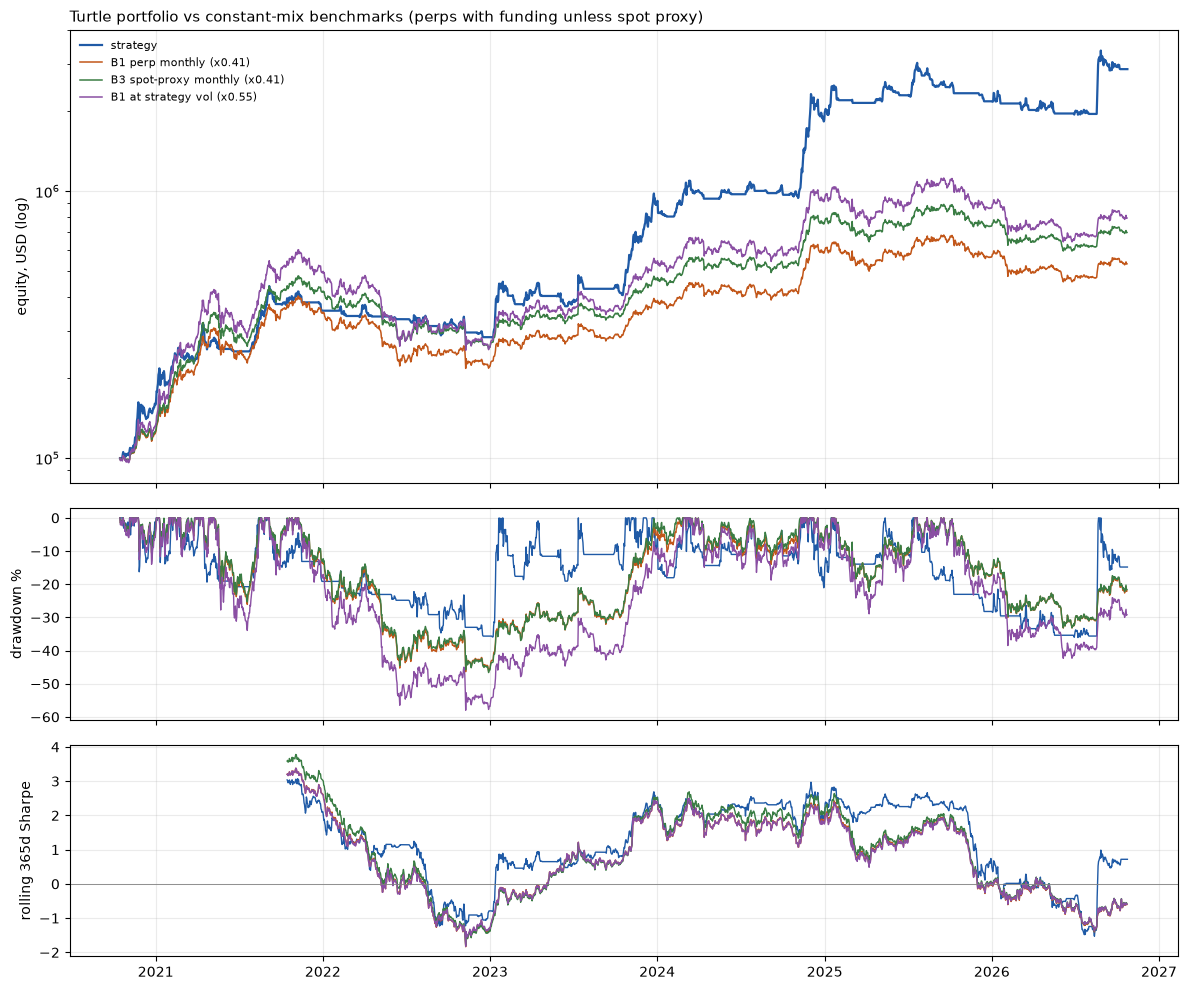

In [6]:
cols = {'strategy': '#1f5aa6', 'B1 perp monthly': '#c2571a', 'B3 spot-proxy monthly': '#3a7d44', 'B1 at strategy vol': '#8a4fa3'}
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1.4, 1.4]})
for k, c in cols.items():
    S = tb.daily(E if k == 'strategy' else B[k])
    lab = k if k == 'strategy' else (f'{k} (x{LEV:.2f})' if 'strategy vol' not in k else f'{k} (x{L_VOL:.2f})')
    axes[0].plot(S.index, S, color=c, lw=1.6 if k == 'strategy' else 1.1, label=lab)
    axes[1].plot(S.index, 100 * (S / S.cummax() - 1), color=c, lw=1.0)
    rs = bm.rolling_sharpe(E if k == 'strategy' else B[k]); axes[2].plot(rs.index, rs, color=c, lw=1.0)
axes[0].set_yscale('log'); axes[0].set_ylabel('equity, USD (log)'); axes[0].legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_title('Turtle portfolio vs constant-mix benchmarks (perps with funding unless spot proxy)', loc='left', fontsize=11)
axes[1].set_ylabel('drawdown %'); axes[2].set_ylabel('rolling 365d Sharpe'); axes[2].axhline(0, color='0.5', lw=0.6)
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Exports

In [7]:
pd.DataFrame({'strategy': tb.daily(E), **{k: tb.daily(v) for k, v in B.items()}}).to_csv(OUT / '02_equity_daily.csv', float_format='%.2f')
TAB.to_csv(OUT / '02_benchmarks.csv', float_format='%.6g')
pd.DataFrame({**TESTS, **rep}).T.to_csv(OUT / '02_sharpe_tests.csv', float_format='%.6g')
YR.to_csv(OUT / '02_yearly.csv', float_format='%.6g'); HV.to_csv(OUT / '02_halves.csv', index=False, float_format='%.6g')
(OUT / '02_decision.json').write_text(json.dumps({'decision': DEC, 'alpha_beta_vs_B1_x1': AB, 'strategy': {k: m[k] for k in ('start', 'end', 'cagr', 'sharpe', 'max_dd', 'trades')},
    'mean_leverage': LEV, 'vol_matched_leverage': L_VOL, 'registration': bm.registration(BP)}, indent=1, default=float))
(OUT / '02_manifest.json').write_text(json.dumps({'module': 'Turtle_Breakout_02', 'version': bm.VERSION, 'synthetic': SYNTHETIC,
    'window': [str(tb.COMMON_START), str(END)], 'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['02_benchmarks.csv', '02_decision.json', '02_equity_daily.csv', '02_halves.csv', '02_manifest.json', '02_sharpe_tests.csv', '02_yearly.csv']
